In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("/content/Bengaluru_House_Data.csv")

In [ ]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [ ]:
df.tail()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.0
13319,Super built-up Area,Ready To Move,Doddathoguru,1 BHK,NaN,550,1.0,1.0,17.0


In [ ]:
df.shape

(13320, 9)

In [ ]:
df.columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [ ]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [ ]:
df.isnull().sum()

,0
area_type,0
availability,0
location,1
size,16
society,5502
total_sqft,0
bath,73
balcony,609
price,0


#Drop and fill missing values

In [ ]:
df = df.dropna(subset=['location'])

In [ ]:
df = df.dropna(subset=['size'])

In [ ]:
df['bath'] = df['bath'].fillna(df['bath'].median())

In [ ]:
df['balcony'] = df['balcony'].fillna(df['balcony'].median())

In [ ]:
df.drop('society', axis=1, inplace=True)

In [ ]:
df.isnull().sum()

,0
area_type,0
availability,0
location,0
size,0
total_sqft,0
bath,0
balcony,0
price,0


#Extract BHK from Size Column

In [ ]:
df['bhk'] = df['size'].apply(lambda x: int(x.split()[0]))

In [ ]:
df[['size', 'bhk']].head()

,size,bhk
0,2 BHK,2
1,4 Bedroom,4
2,3 BHK,3
3,3 BHK,3
4,2 BHK,2


In [ ]:
df = df.drop('size', axis=1)

In [ ]:
df.head()

,area_type,availability,location,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,1056,2.0,1.0,39.07,2
1,Plot Area,Ready To Move,Chikka Tirupathi,2600,5.0,3.0,120.00,4
2,Built-up Area,Ready To Move,Uttarahalli,1440,2.0,3.0,62.00,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,1521,3.0,1.0,95.00,3
4,Super built-up Area,Ready To Move,Kothanur,1200,2.0,1.0,51.00,2


#Check Unique Total Square Feet Values

In [ ]:
df['total_sqft'].unique()[:20]

array(['1056', '2600', '1440', '1521', '1200', '1170', '2732', '3300',
       '1310', '1020', '1800', '2785', '1000', '1100', '2250', '1175',
       '1180', '1540', '2770', '600'], dtype=object)

#Convert Total Square Feet Values into Numeric Format

In [ ]:
def convert_sqft_to_num(x):
    try:
        return float(x)
    except:
        try:
            values = x.split('-')
            return (float(values[0]) + float(values[1])) / 2
        except:
            return None

#Apply the Square Feet Conversion Function to the Total Sq. Ft. Column

In [ ]:
df['total_sqft'] = df['total_sqft'].apply(convert_sqft_to_num)

In [ ]:
df.head()

,area_type,availability,location,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,1056.0,2.0,1.0,39.07,2
1,Plot Area,Ready To Move,Chikka Tirupathi,2600.0,5.0,3.0,120.00,4
2,Built-up Area,Ready To Move,Uttarahalli,1440.0,2.0,3.0,62.00,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,1521.0,3.0,1.0,95.00,3
4,Super built-up Area,Ready To Move,Kothanur,1200.0,2.0,1.0,51.00,2


In [ ]:
df = df.dropna(subset=['total_sqft'])

In [ ]:
df.isnull().sum()

,0
area_type,0
availability,0
location,0
total_sqft,0
bath,0
balcony,0
price,0
bhk,0


In [ ]:
df.head()

,area_type,availability,location,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,1056.0,2.0,1.0,39.07,2
1,Plot Area,Ready To Move,Chikka Tirupathi,2600.0,5.0,3.0,120.00,4
2,Built-up Area,Ready To Move,Uttarahalli,1440.0,2.0,3.0,62.00,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,1521.0,3.0,1.0,95.00,3
4,Super built-up Area,Ready To Move,Kothanur,1200.0,2.0,1.0,51.00,2


#Calculate Price Per Square Foot

In [ ]:
df['price_per_sqft'] = df['price'] * 100000 / df['total_sqft']

/tmp/ipykernel_3339/4168263592.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['price_per_sqft'] = df['price'] * 100000 / df['total_sqft']


In [ ]:
df.describe()

,total_sqft,bath,balcony,price,bhk,price_per_sqft
count,13257.000000,13257.000000,13257.000000,13257.000000,13257.000000,1.325700e+04
mean,1558.809175,2.688165,1.604058,112.471981,2.802670,7.912825e+03
std,1238.478935,1.336799,0.802958,149.092716,1.292117,1.064976e+05
min,1.000000,1.000000,0.000000,8.000000,1.000000,2.678298e+02
25%,1100.000000,2.000000,1.000000,50.000000,2.000000,4.271186e+03
50%,1275.000000,2.000000,2.000000,72.000000,3.000000,5.438596e+03
75%,1680.000000,3.000000,2.000000,120.000000,3.000000,7.313318e+03
max,52272.000000,40.000000,3.000000,3600.000000,43.000000,1.200000e+07


In [ ]:
len(df['location'].unique())

1298

In [ ]:
location_counts = df['location'].value_counts()

location_counts.head(20)

,count
location,
Whitefield,537
Sarjapur Road,397
Electronic City,302
Kanakpura Road,271
Thanisandra,233
Yelahanka,212
Uttarahalli,186
Hebbal,177
Marathahalli,175


#Handle Rare Locations by Grouping Them into 'Other'

In [ ]:
location_counts = df['location'].value_counts()

locations_less_than_10 = location_counts[location_counts <= 10]

df['location'] = df['location'].apply(
    lambda x: 'other' if x in locations_less_than_10 else x
)

/tmp/ipykernel_3339/1101017571.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['location'] = df['location'].apply(


In [ ]:
len(df['location'].unique())

241

#Identify Houses with Less Than 300 Sq. Ft. per Bedroom

In [ ]:
df[df['total_sqft'] / df['bhk'] < 300].head()

,area_type,availability,location,total_sqft,bath,balcony,price,bhk,price_per_sqft
9,Plot Area,Ready To Move,other,1020.0,6.0,2.0,370.0,6,36274.509804
45,Plot Area,Ready To Move,HSR Layout,600.0,9.0,2.0,200.0,8,33333.333333
58,Plot Area,Ready To Move,Murugeshpalya,1407.0,4.0,1.0,150.0,6,10660.980810
68,Plot Area,Ready To Move,other,1350.0,7.0,0.0,85.0,8,6296.296296
70,Plot Area,Ready To Move,other,500.0,3.0,2.0,100.0,3,20000.000000


#Remove Houses with Less Than 300 Sq. Ft. per Bedroom

In [ ]:
df = df[~(df['total_sqft'] / df['bhk'] < 300)]

In [ ]:
def remove_pps_outliers(df):
    df_out = pd.DataFrame()

    for key, subdf in df.groupby('location'):
        mean = subdf['price_per_sqft'].mean()
        std = subdf['price_per_sqft'].std()

        reduced_df = subdf[
            (subdf['price_per_sqft'] > (mean - std)) &
            (subdf['price_per_sqft'] < (mean + std))
        ]

        df_out = pd.concat([df_out, reduced_df], ignore_index=True)

    return df_out

In [ ]:
df = remove_pps_outliers(df)

In [ ]:
df['price_per_sqft']

,price_per_sqft
0,3520.000000
1,3200.000000
2,6916.666667
3,3418.803419
4,4561.403509
...,...
10335,8130.081301
10336,3201.970443
10337,4439.583333
10338,4465.116279


In [ ]:
df = remove_pps_outliers(df)

#Calculate Price Per Square Foot

In [ ]:
df['price_per_sqft'] = df['price'] * 100000 / df['total_sqft']

#Visualize House Price vs. Total Square Feet by BHK Using a Scatter Plot

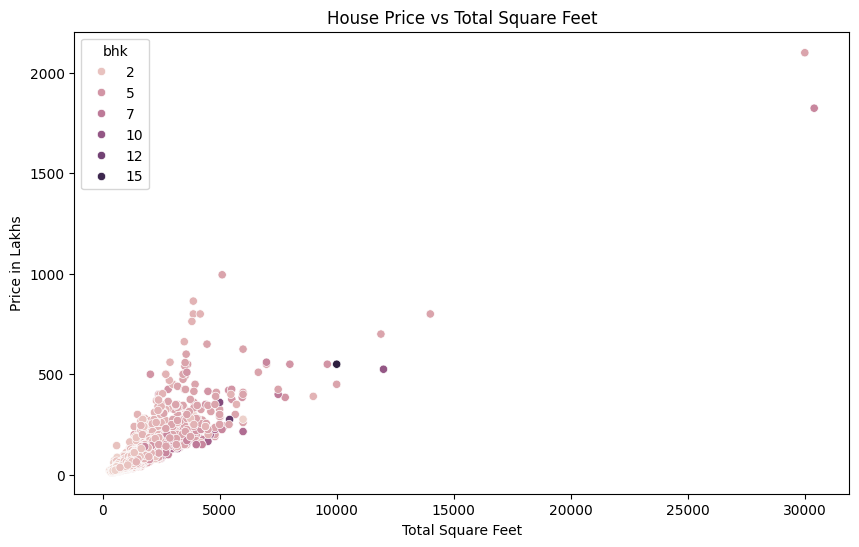

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='total_sqft',
    y='price',
    hue='bhk'
)

plt.xlabel('Total Square Feet')
plt.ylabel('Price in Lakhs')
plt.title('House Price vs Total Square Feet')

plt.show()

#Compare House Prices and Total Square Feet for 2-BHK and 3-BHK Houses Using a Scatter Plot

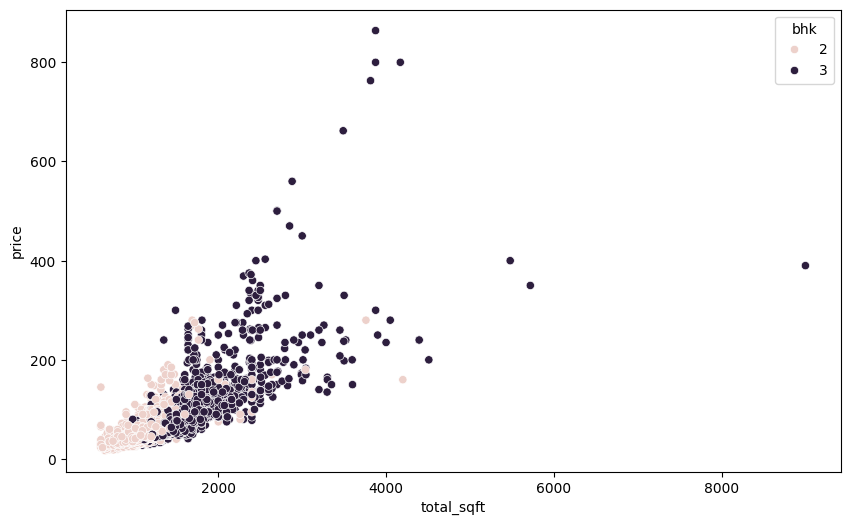

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df[df['bhk'].isin([2,3])],
    x='total_sqft',
    y='price',
    hue='bhk'
)

plt.show()

In [ ]:
df['bath'].value_counts()

,count
bath,
2.0,4295
3.0,1784
4.0,406
1.0,404
5.0,118
6.0,56
7.0,16
8.0,9
9.0,3


#Identify Houses with More Than Two Extra Bathrooms Compared to Bedrooms

In [ ]:
df[df['bath'] > df['bhk'] + 2]

,area_type,availability,location,total_sqft,bath,balcony,price,bhk,price_per_sqft
1142,Built-up Area,Ready To Move,Chikkabanavar,2460.0,7.0,2.0,80.0,4,3252.03252
4519,Super built-up Area,Ready To Move,Thanisandra,1806.0,6.0,2.0,116.0,3,6423.03433


In [ ]:
df = df[df['bath'] < df['bhk'] + 2]

In [ ]:
df = df[['location', 'total_sqft', 'bath', 'bhk', 'price']]

In [ ]:
df.head()

,location,total_sqft,bath,bhk,price
0,Devarachikkanahalli,1250.0,2.0,3,44.0
1,Devarachikkanahalli,1170.0,2.0,2,40.0
2,Devarachikkanahalli,1425.0,2.0,3,65.0
3,Devarachikkanahalli,947.0,2.0,2,43.0
4,Devarachikkanahalli,1230.0,2.0,2,58.0


#Convert Location Categories into Dummy Variables Using One-Hot Encoding

In [ ]:
dummies = pd.get_dummies(df['location'])

In [ ]:
dummies.head()

,Devarachikkanahalli,1st Block Jayanagar,1st Phase JP Nagar,2nd Phase Judicial Layout,2nd Stage Nagarbhavi,5th Block Hbr Layout,5th Phase JP Nagar,6th Phase JP Nagar,7th Phase JP Nagar,8th Phase JP Nagar,...,Vishveshwarya Layout,Vishwapriya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur,other
0,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


#Combine Dummy Variables with the Dataset and Remove the Original Location Column

In [ ]:
df2 = pd.concat([df.drop('location', axis=1), dummies.drop('other', axis=1)], axis=1)

In [ ]:
df2.head()

,total_sqft,bath,bhk,price,Devarachikkanahalli,1st Block Jayanagar,1st Phase JP Nagar,2nd Phase Judicial Layout,2nd Stage Nagarbhavi,5th Block Hbr Layout,...,Vijayanagar,Vishveshwarya Layout,Vishwapriya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur
0,1250.0,2.0,3,44.0,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1170.0,2.0,2,40.0,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1425.0,2.0,3,65.0,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,947.0,2.0,2,43.0,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1230.0,2.0,2,58.0,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
X = df2.drop('price', axis=1)

y = df2['price']

In [ ]:
X.head()

,total_sqft,bath,bhk,Devarachikkanahalli,1st Block Jayanagar,1st Phase JP Nagar,2nd Phase Judicial Layout,2nd Stage Nagarbhavi,5th Block Hbr Layout,5th Phase JP Nagar,...,Vijayanagar,Vishveshwarya Layout,Vishwapriya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur
0,1250.0,2.0,3,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1170.0,2.0,2,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1425.0,2.0,3,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,947.0,2.0,2,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1230.0,2.0,2,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
y.head()

,price
0,44.0
1,40.0
2,65.0
3,43.0
4,58.0


#Split the Dataset into Training and Testing Sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=10
)

#Create and Train the Linear Regression Model

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

#Predict House Prices Using the Trained Linear Regression Model

In [ ]:
y_pred = model.predict(X_test)

#Evaluate the Model Using the R² Score

In [ ]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.9271840842133638


#Evaluate the Model Using Mean Absolute Error (MAE)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 11.094576416901443


#Evaluate the Model Using Root Mean Squared Error (RMSE)

In [ ]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 20.811025038504127


In [ ]:
X.columns

Index(['total_sqft', 'bath', 'bhk', ' Devarachikkanahalli',
       '1st Block Jayanagar', '1st Phase JP Nagar',
       '2nd Phase Judicial Layout', '2nd Stage Nagarbhavi',
       '5th Block Hbr Layout', '5th Phase JP Nagar',
       ...
       'Vijayanagar', 'Vishveshwarya Layout', 'Vishwapriya Layout',
       'Vittasandra', 'Whitefield', 'Yelachenahalli', 'Yelahanka',
       'Yelahanka New Town', 'Yelenahalli', 'Yeshwanthpur'],
      dtype='object', length=243)

#Create a House Price Prediction Function Based on Location, Square Feet, Bathrooms, and BHK

In [ ]:
def predict_price(location, sqft, bath, bhk):

    loc_index = np.where(X.columns == location)[0][0]

    x = np.zeros(len(X.columns))

    x[0] = sqft
    x[1] = bath
    x[2] = bhk

    if loc_index >= 0:
        x[loc_index] = 1

    return model.predict([x])[0]

#Predict the House Price for a Specific Location and House Details

In [ ]:
predict_price('Whitefield', 1200, 2, 2)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


np.float64(64.51784626785839)

In [ ]:
predict_price('Electronic City', 1500, 3, 3)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


np.float64(70.79979281070025)

In [ ]:
predict_price('Rajaji Nagar', 1800, 3, 3)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


np.float64(272.31078383795136)